# Analisis Eksplorasi Data (EDA) & Data Preprocessing
## Studi Kasus: Retail Products Classification Dataset
**Mata Kuliah**: Machine Learning (COMP657701) - Session 03-04  
**Dataset**: `project/dataset/barudownload/retail-products-classification/train.csv` (46.229 baris data produk)
**Output Preprocessed**: `project_fix/data/retail_products_preprocessed.csv`  

---
### Outline Berdasarkan `materi.md`:
1. **Exploratory Data Analysis (EDA) - Matriks 2x2**:
   - **Univariat Non-Grafis**: Central tendency, spread, skewness, kurtosis, dan tabulasi frekuensi kategori target.
   - **Univariat Grafis**: Histogram dan Boxplot untuk mendeteksi pencilan (outliers).
   - **Multivariat Non-Grafis**: Cross-tabulation dan korelasi antar fitur.
   - **Multivariat Grafis**: Visualisasi bivariat (Barplot rata-rata panjang teks per kategori, Scatterplot korelasi).
2. **Data Preprocessing**:
   - **Data Cleaning**: Penanganan missing values dan pembersihan tag HTML/noise teks.
   - **Feature Engineering**: Ekstraksi panjang karakter dan jumlah kata dari judul serta deskripsi.
   - **Encoding**: Label Encoding pada variabel target kategorikal `categories`.
   - **Normalisasi & Standardisasi**: Min-Max Scaling dan Z-score Standardization.
   - **Diskretisasi**: Pengelompokan panjang deskripsi menjadi interval `Low`, `Medium`, dan `High` sesuai formula materi.

## 1. Import Libraries & Setup Environment

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

# Setting visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

## 2. Load Dataset Mentah (Raw Data)
Dataset dibaca langsung dari folder `project/dataset/barudownload/retail-products-classification/`.

In [2]:
raw_path = '../../project/dataset/barudownload/retail-products-classification/train.csv'
df_raw = pd.read_csv(raw_path)
print(f"Dimensi Dataset Mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
df_raw.head()

Dimensi Dataset Mentah: 46229 baris, 4 kolom


,ImgId,title,description,categories
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing"
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry"
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care


--- 
# BAGIAN A: Exploratory Data Analysis (EDA)
Sesuai kerangka **Matriks 2x2 Teknik EDA** pada `materi.md`.

### A.1 Univariat Non-Grafis
#### 1. Tabulasi Frekuensi Variabel Kategorikal (`categories`)

In [3]:
cat_freq = df_raw['categories'].value_counts()
cat_pct = df_raw['categories'].value_counts(normalize=True) * 100

freq_table = pd.DataFrame({
    'Jumlah Sampel': cat_freq,
    'Persentase (%)': cat_pct.round(2)
})
print("=== Tabulasi Frekuensi Kategori Produk (Target) ===")
freq_table

=== Tabulasi Frekuensi Kategori Produk (Target) ===


,Jumlah Sampel,Persentase (%)
categories,,
"Arts, Crafts & Sewing",2225,4.81
Beauty,2202,4.76
Sports & Outdoors,2201,4.76
Grocery & Gourmet Food,2201,4.76
Cell Phones & Accessories,2200,4.76
Health & Personal Care,2200,4.76
Tools & Home Improvement,2200,4.76
"Clothing, Shoes & Jewelry",2200,4.76
Baby,2200,4.76


#### 2. Central Tendency, Spread, Skewness & Kurtosis (Fitur Panjang Teks)
Mengekstrak panjang karakter dan jumlah kata sebagai fitur kuantitatif untuk diuji distribusinya.

In [4]:
# Ekstraksi panjang teks sementara
df_raw['title_len'] = df_raw['title'].fillna('').astype(str).apply(len)
df_raw['title_words'] = df_raw['title'].fillna('').astype(str).apply(lambda x: len(x.split()))
df_raw['desc_len'] = df_raw['description'].fillna('').astype(str).apply(len)
df_raw['desc_words'] = df_raw['description'].fillna('').astype(str).apply(lambda x: len(x.split()))

num_cols = ['title_len', 'title_words', 'desc_len', 'desc_words']
stats_rows = []

for c in num_cols:
    s = df_raw[c]
    q75, q25 = np.percentile(s, [75, 25])
    stats_rows.append({
        'Fitur': c,
        'Mean': round(s.mean(), 2),
        'Median': round(s.median(), 2),
        'Std Dev': round(s.std(), 2),
        'Varians': round(s.var(), 2),
        'IQR': round(q75 - q25, 2),
        'Min': s.min(),
        'Max': s.max(),
        'Skewness': round(s.skew(), 2),
        'Kurtosis': round(s.kurt(), 2)
    })

stats_df = pd.DataFrame(stats_rows).set_index('Fitur')
print("=== Statistik Deskriptif Univariat Non-Grafis ===")
stats_df

=== Statistik Deskriptif Univariat Non-Grafis ===


,Mean,Median,Std Dev,Varians,IQR,Min,Max,Skewness,Kurtosis
Fitur,,,,,,,,,
title_len,54.54,49.0,29.93,895.53,29.0,0,549,2.85,17.67
title_words,8.46,7.0,4.75,22.58,4.0,0,89,3.10,20.11
desc_len,474.06,303.0,627.14,393301.53,455.0,0,20082,6.90,117.55
desc_words,73.87,48.0,92.42,8541.82,72.0,0,1953,4.86,45.05


### A.2 Univariat Grafis (Histogram & Boxplot)
Sesuai `materi.md`, histogram digunakan untuk melihat bentuk kurva distribusi data, sedangkan boxplot digunakan untuk mendeteksi keberadaan outlier (pencilan).

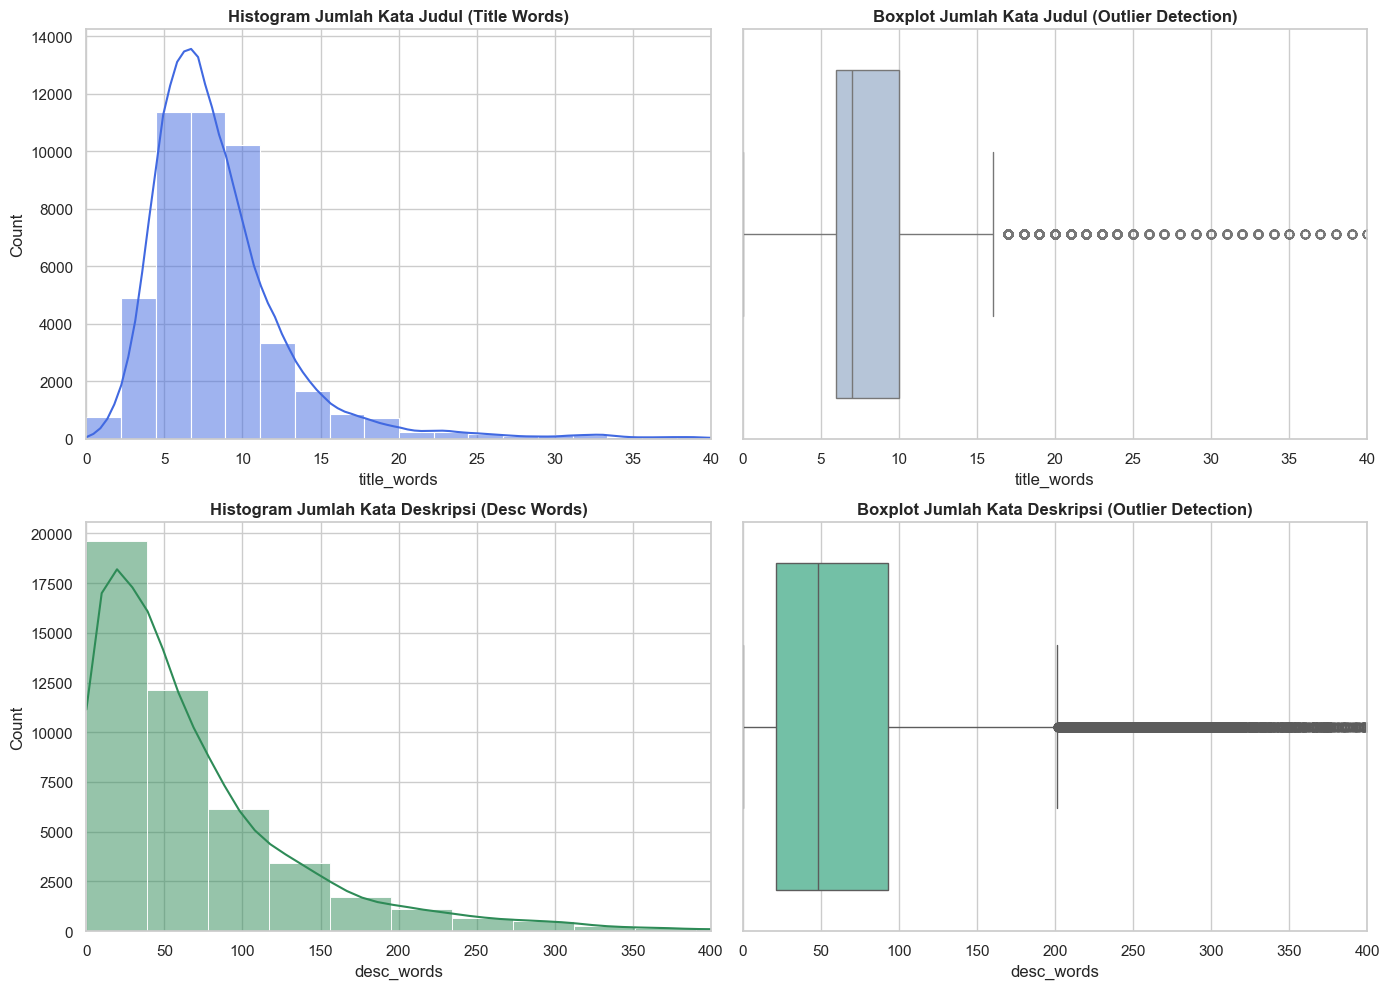

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram Panjang Judul (Kata)
sns.histplot(df_raw['title_words'], bins=40, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Histogram Jumlah Kata Judul (Title Words)', fontweight='bold')
axes[0, 0].set_xlim(0, 40)

# 2. Boxplot Panjang Judul (Kata) - Deteksi Outlier
sns.boxplot(x=df_raw['title_words'], ax=axes[0, 1], color='lightsteelblue')
axes[0, 1].set_title('Boxplot Jumlah Kata Judul (Outlier Detection)', fontweight='bold')
axes[0, 1].set_xlim(0, 40)

# 3. Histogram Jumlah Kata Deskripsi
sns.histplot(df_raw['desc_words'], bins=50, kde=True, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Histogram Jumlah Kata Deskripsi (Desc Words)', fontweight='bold')
axes[1, 0].set_xlim(0, 400)

# 4. Boxplot Jumlah Kata Deskripsi - Deteksi Outlier
sns.boxplot(x=df_raw['desc_words'], ax=axes[1, 1], color='mediumaquamarine')
axes[1, 1].set_title('Boxplot Jumlah Kata Deskripsi (Outlier Detection)', fontweight='bold')
axes[1, 1].set_xlim(0, 400)

plt.tight_layout()
plt.show()

### A.3 Multivariat Non-Grafis (Korelasi & Rata-rata per Kategori)

In [6]:
print("=== Matriks Korelasi Pearson Antar Fitur Teks ===")
corr_matrix = df_raw[['title_len', 'title_words', 'desc_len', 'desc_words']].corr()
print(corr_matrix.round(4))

print("\n=== Rata-rata Karakteristik Teks Berdasarkan Kategori ===")
cat_summary = df_raw.groupby('categories')[['title_words', 'desc_words']].agg(['mean', 'median']).round(2)
cat_summary

=== Matriks Korelasi Pearson Antar Fitur Teks ===
             title_len  title_words  desc_len  desc_words
title_len       1.0000       0.9523    0.0798      0.0762
title_words     0.9523       1.0000    0.0577      0.0565
desc_len        0.0798       0.0577    1.0000      0.9833
desc_words      0.0762       0.0565    0.9833      1.0000

=== Rata-rata Karakteristik Teks Berdasarkan Kategori ===


title_words        desc_words       
                                 mean median       mean median
categories                                                    
All Beauty                       9.62    9.0      57.52   45.0
All Electronics                  9.38    8.0      92.04   52.0
Appliances                       8.02    7.0      52.83   27.0
Arts, Crafts & Sewing            7.78    7.0      59.75   45.0
Automotive                       8.22    7.0      53.50   37.0
Baby                             6.66    6.0      80.71   59.0
Baby Products                    8.43    8.0      70.16   49.5
Beauty                           8.81    9.0      65.17   47.0
Cell Phones & Accessories       14.14   11.0      96.13   54.0
Clothing, Shoes & Jewelry        7.13    7.0      55.03   39.0
Electronics                      9.81    8.0     118.73   79.0
Grocery & Gourmet Food           6.97    7.0      58.39   40.0
Health & Personal Care           8.23    8.0      81.79   52.0
Industrial & Scientific          9.82    9.0      56.13   37.0
Musical Instruments              7.41    7.0      63.50   40.0
Office Products                  8.33    7.0      96.06   69.0
Patio, Lawn & Garden             8.64    8.0      93.50   69.0
Pet Supplies                     7.21    7.0      55.80   43.0
Sports & Outdoors                6.90    6.0      59.79   39.0
Tools & Home Improvement         9.09    8.0      83.32   53.0
Toys & Games                     7.13    6.0     101.60   97.0

### A.4 Multivariat Grafis
Visualisasi perbandingan jumlah kata judul dan deskripsi lintas 21 kategori produk ritel.

C:\Users\farha\AppData\Local\Temp\ipykernel_26372\3310868500.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_raw, y='categories', x='title_words', order=order, palette='crest', errorbar=None, ax=ax)


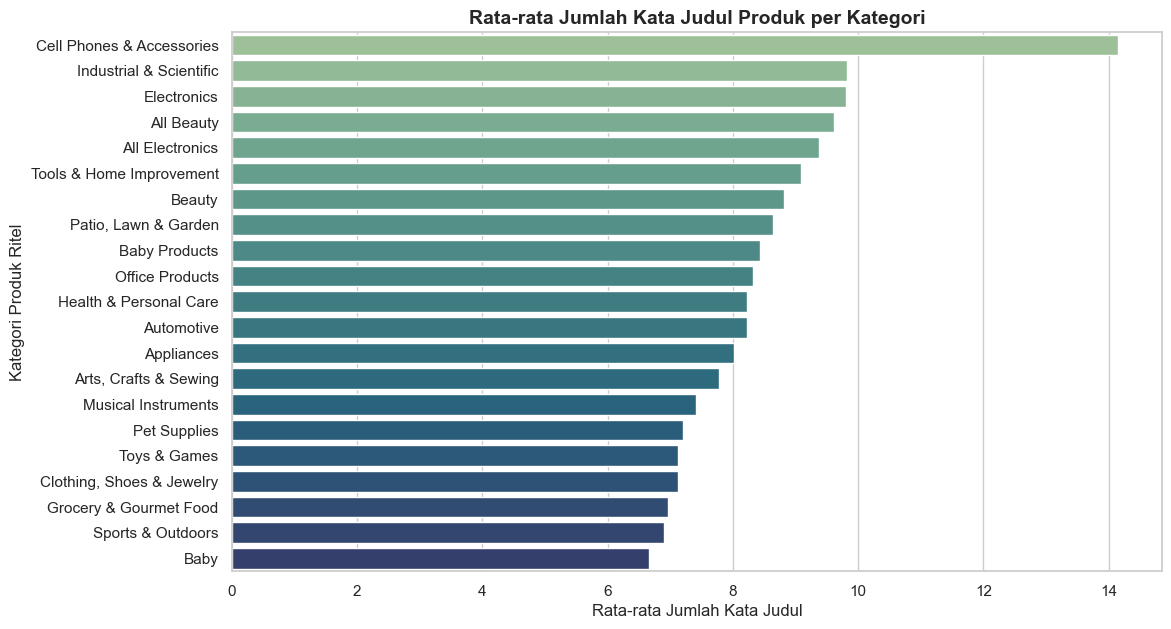

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
order = df_raw.groupby('categories')['title_words'].mean().sort_values(ascending=False).index
sns.barplot(data=df_raw, y='categories', x='title_words', order=order, palette='crest', errorbar=None, ax=ax)
ax.set_title('Rata-rata Jumlah Kata Judul Produk per Kategori', fontsize=14, fontweight='bold')
ax.set_xlabel('Rata-rata Jumlah Kata Judul')
ax.set_ylabel('Kategori Produk Ritel')
plt.show()

--- 
# BAGIAN B: Data Preprocessing
Meliputi: **Data Cleaning**, **Integration/Transformation**, **Encoding**, **Scaling**, dan **Discretization**.

### B.1 Data Cleaning (Penanganan Missing Values & Noise Teks)
- Mengecek keberadaan missing value.
- Menghapus 1 baris judul kosong (karena judul merupakan identifier esensial produk).
- Mengisi 1.042 deskripsi kosong dengan string kosong `''`.
- Membersihkan tag HTML (noise) dan format whitespace menggunakan Regular Expressions.

In [8]:
print("Missing values sebelum cleaning:")
print(df_raw[['ImgId', 'title', 'description', 'categories']].isnull().sum())

# 1. Drop missing title
df_clean = df_raw.dropna(subset=['title']).copy()

# 2. Imputasi missing description
df_clean['description'] = df_clean['description'].fillna('')

# 3. Noise removal function
def clean_noise(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'<[^>]+>', ' ', text)           # Hapus tag HTML
    text = re.sub(r'http\S+|www\.\S+', ' ', text)  # Hapus URL
    text = re.sub(r'&amp;|&lt;|&gt;', ' ', text)   # Hapus entitas HTML
    text = re.sub(r'\s+', ' ', text)               # Normalisasi spasi ganda
    return text.strip()

df_clean['clean_title'] = df_clean['title'].apply(clean_noise)
df_clean['clean_desc'] = df_clean['description'].apply(clean_noise)
df_clean['combined_text'] = df_clean['clean_title'] + ' ' + df_clean['clean_desc']

print(f"\nTotal data setelah cleaning: {len(df_clean)} baris (1 data title kosong dieliminasi)")

Missing values sebelum cleaning:
ImgId             0
title             1
description    1042
categories        0
dtype: int64

Total data setelah cleaning: 46228 baris (1 data title kosong dieliminasi)


### B.2 Feature Engineering (Ekstraksi Karakteristik Teks)
Membuat fitur representasi numerik: panjang karakter dan jumlah kata.

In [9]:
df_clean['title_char_len'] = df_clean['clean_title'].apply(len)
df_clean['title_word_count'] = df_clean['clean_title'].apply(lambda x: len(x.split()))
df_clean['desc_char_len'] = df_clean['clean_desc'].apply(len)
df_clean['desc_word_count'] = df_clean['clean_desc'].apply(lambda x: len(x.split()))

df_clean[['clean_title', 'title_word_count', 'desc_word_count']].head(3)

,clean_title,title_word_count,desc_word_count
0,TUNGSTEN SOLDER PICK WITH HANDLE,5,10
1,Write Right 98167 Screen Protector for Sony T615C,8,67
2,Casio Mens DBC310-1 Databank 300 Digital Watch...,10,99


### B.3 Encoding Variabel Kategorikal (Label Encoding)
Sesuai `materi.md`: algoritma Machine Learning membutuhkan representasi numerik untuk target kelas klasifikasi.

In [10]:
label_encoder = LabelEncoder()
df_clean['category_encoded'] = label_encoder.fit_transform(df_clean['categories'])

mapping_df = pd.DataFrame({
    'Kategori Asli': label_encoder.classes_,
    'Kode Terenkripsi': range(len(label_encoder.classes_))
})
print("=== Pemetaan Label Encoding (21 Kategori) ===")
mapping_df.head(10)

=== Pemetaan Label Encoding (21 Kategori) ===


,Kategori Asli,Kode Terenkripsi
0,All Beauty,0
1,All Electronics,1
2,Appliances,2
3,"Arts, Crafts & Sewing",3
4,Automotive,4
5,Baby,5
6,Baby Products,6
7,Beauty,7
8,Cell Phones & Accessories,8
9,"Clothing, Shoes & Jewelry",9


### B.4 Normalisasi & Standardisasi Fitur Numerik
Sesuai `materi.md`:
1. **Min-Max Normalization**: Menskalakan fitur ke rentang `[0, 1]`.
2. **Z-score Standardization**: Mentransformasi fitur agar memiliki $\mu=0$ dan $\sigma=1$.

In [11]:
# 1. Min-Max Scaling [0, 1]
minmax = MinMaxScaler()
df_clean[['title_char_len_minmax', 'desc_word_count_minmax']] = minmax.fit_transform(
    df_clean[['title_char_len', 'desc_word_count']]
)

# 2. Z-Score Scaling (StandardScaler)
std_scaler = StandardScaler()
df_clean[['title_char_len_zscore', 'desc_word_count_zscore']] = std_scaler.fit_transform(
    df_clean[['title_char_len', 'desc_word_count']]
)

print("Contoh Hasil Penskalaan (Scaling):")
df_clean[['title_char_len', 'title_char_len_minmax', 'title_char_len_zscore', 'desc_word_count_minmax', 'desc_word_count_zscore']].head(5)

Contoh Hasil Penskalaan (Scaling):


,title_char_len,title_char_len_minmax,title_char_len_zscore,desc_word_count_minmax,desc_word_count_zscore
0,32,0.053704,-0.753048,0.005120,-0.699131
1,49,0.085185,-0.182088,0.034306,-0.073803
2,77,0.137037,0.758317,0.050691,0.277258
3,71,0.125926,0.556802,0.004096,-0.721072
4,22,0.035185,-1.088907,0.023554,-0.304187


### B.5 Diskretisasi Fitur Kontinu (Data Discretization)
Sesuai formula contoh di `materi.md`:
- Jika $X > 2 \times \text{AVG} \rightarrow \textbf{High}$
- Jika $X < 0.5 \times \text{AVG} \rightarrow \textbf{Low}$
- Selain itu $\rightarrow \textbf{Medium}$

In [12]:
avg_desc_words = df_clean['desc_word_count'].mean()
print(f"Rata-rata kata deskripsi (AVG): {avg_desc_words:.2f} kata\n")

def discretize_desc_length(val):
    if val > 2 * avg_desc_words:
        return 'High'
    elif val < 0.5 * avg_desc_words:
        return 'Low'
    else:
        return 'Medium'

df_clean['desc_word_count_disc'] = df_clean['desc_word_count'].apply(discretize_desc_length)

print("=== Distribusi Kategori Hasil Diskretisasi ===")
print(df_clean['desc_word_count_disc'].value_counts())
print(df_clean['desc_word_count_disc'].value_counts(normalize=True) * 100)

Rata-rata kata deskripsi (AVG): 73.73 kata

=== Distribusi Kategori Hasil Diskretisasi ===
desc_word_count_disc
Medium    22409
Low       18246
High       5573
Name: count, dtype: int64
desc_word_count_disc
Medium    48.474950
Low       39.469586
High      12.055464
Name: proportion, dtype: float64


## 3. Ekspor Dataset Hasil Preprocessing ke `project_fix/data/`

In [13]:
out_csv = '../data/retail_products_preprocessed.csv'
df_clean.to_csv(out_csv, index=False)
print(f"File berhasil disimpan ke: {out_csv}")
print(f"Total baris: {df_clean.shape[0]}, Total kolom: {df_clean.shape[1]}")

File berhasil disimpan ke: ../data/retail_products_preprocessed.csv
Total baris: 46228, Total kolom: 21
